In [850]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Libraries loaded successfully.")

TensorFlow version: 2.17.0
Libraries loaded successfully.


In [851]:
model = tf.keras.models.load_model(
    "skin_disease_vgg16_model.h5"
)

print("Model loaded successfully.")
print("Model input shape:", model.input_shape)

Model loaded successfully.
Model input shape: (None, 150, 150, 3)


In [852]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │     4,194,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 18,910,019 (72.14 MB)

Trainable params: 4,195,329 (16.00 MB)

Non-trainable params: 14,714,688 (56.13 MB)

Optimizer params: 2 (12.00 B)

In [853]:
base_model = model.layers[0]

print("Base model:", base_model.name)
print("Base model input:", base_model.input_shape)
print("Base model output:", base_model.output_shape)

Base model: vgg16
Base model input: (None, 150, 150, 3)
Base model output: (None, 4, 4, 512)


In [854]:
conv_layer = base_model.get_layer("block5_conv3")

print("Grad-CAM layer:", conv_layer.name)

Grad-CAM layer: block5_conv3


In [855]:
rescale=1.0 / 255.0

In [856]:
IMG_SIZE = 150

def preprocess_image(img_path):

    img = tf.keras.utils.load_img(
        img_path,
        target_size=(IMG_SIZE, IMG_SIZE)
    )

    img_array = tf.keras.utils.img_to_array(img)

    img_array = img_array / 255.0

    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    return img_array

In [857]:
img_array = preprocess_image(img_path)

print("Image shape:", img_array.shape)
print("Minimum pixel value:", img_array.min())
print("Maximum pixel value:", img_array.max())

Image shape: (1, 150, 150, 3)
Minimum pixel value: 0.101960786
Maximum pixel value: 1.0


In [858]:
img_path = r"C:\Users\usER\dataset Skin\test\benign\700.jpg"

print("Image path:")
print(img_path)

Image path:
C:\Users\usER\dataset Skin\test\benign\700.jpg


In [859]:
pred = model.predict(
    img_array,
    verbose=0
)[0][0]

print("Prediction probability:", float(pred))

Prediction probability: 0.012658635154366493


In [860]:
import tensorflow as tf
import numpy as np

def gradcam(img_array):
    # Get the VGG16 base model
    base_model = model.layers[0]
    
    # Find the target convolutional layer
    target_layer = base_model.get_layer("block5_conv3")
    
    # Create a model that returns:
    # 1. the activation from block5_conv3
    # 2. the final prediction
    grad_model = tf.keras.Model(
        inputs=base_model.input,
        outputs=[target_layer.output, base_model.output]
    )
    
    with tf.GradientTape() as tape:
        conv_outputs, base_output = grad_model(img_array, training=False)
        
        # Pass VGG16 output through the classifier
        x = base_output
        
        for layer in model.layers[1:]:
            x = layer(x, training=False)
        
        predictions = x
        
        # Target the model's output
        loss = predictions[:, 0]
    
    # Calculate gradients
    grads = tape.gradient(loss, conv_outputs)
    
    # Global average pooling of gradients
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    
    # Remove batch dimension
    conv_outputs = conv_outputs[0]
    
    # Weight feature maps by their gradients
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )
    
    # ReLU
    heatmap = tf.maximum(heatmap, 0)
    
    # Normalize to 0–1
    max_value = tf.reduce_max(heatmap)
    
    if max_value > 0:
        heatmap /= max_value
    
    return heatmap.numpy()

In [861]:
heatmap = gradcam(img_array)

print("Heatmap shape:", heatmap.shape)
print("Heatmap minimum:", heatmap.min())
print("Heatmap maximum:", heatmap.max())

Heatmap shape: (9, 9)
Heatmap minimum: 0.0
Heatmap maximum: 1.0


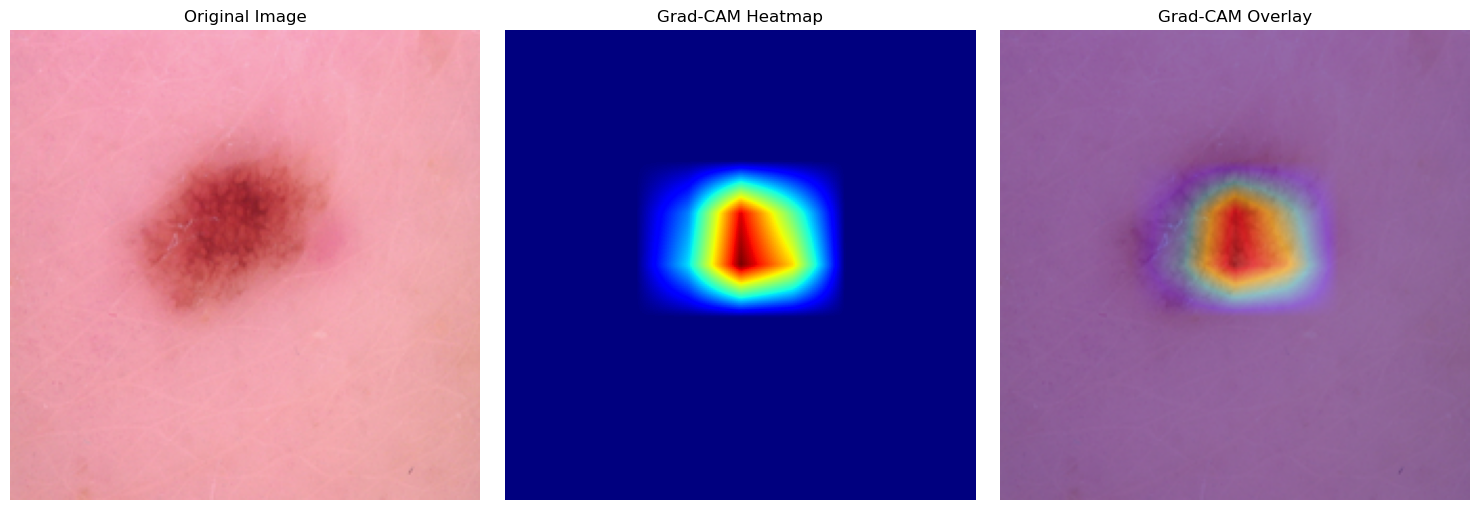

In [862]:
import matplotlib.pyplot as plt
import cv2

# Load the original image
original_img = cv2.imread(img_path)
original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)

# Resize heatmap to original image size
heatmap_resized = cv2.resize(
    heatmap,
    (original_img.shape[1], original_img.shape[0])
)

# Convert heatmap to 0–255
heatmap_uint8 = np.uint8(255 * heatmap_resized)

# Apply JET colormap
heatmap_color = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

# Convert BGR to RGB
heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

# Create overlay
overlay = cv2.addWeighted(
    original_img,
    0.6,
    heatmap_color,
    0.4,
    0
)

# Display
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()